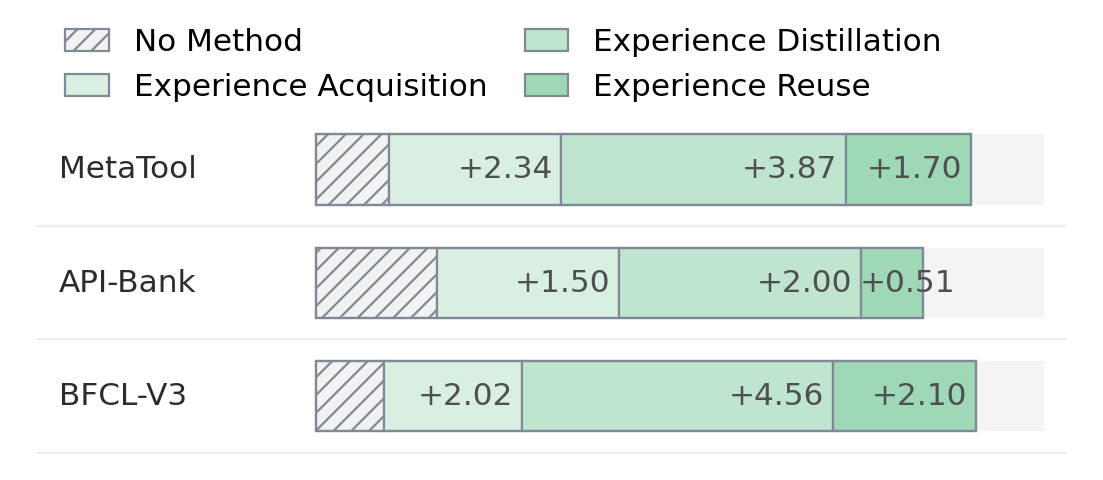

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import numpy as np

plt.rcParams.update({
    "font.size": 14,
    "legend.fontsize": 14,
})

modules = ["No Method", "Experience Acquisition", "Experience Distillation", "Experience Reuse"]
datasets = ["MetaTool", "API-Bank", "BFCL-V3"]

# 累计值（不是增量）
data = {
    "MetaTool": [0.7697, 0.7931, 0.8318, 0.8488],
    "API-Bank": [0.8388, 0.8538, 0.8738, 0.8789],
    "BFCL-V3":  [58.28,  60.30,  64.86,  66.96],
}

# 颜色：No Method 用灰色“网格(hatch)”表示；其余同色系渐变(绿)
c_base_face = "#F2F2F2"
c_mods = ["#D8EFE2", "#BFE5CF", "#9FD8B7"]
seg_faces = [c_base_face] + c_mods
edge = "#7F8A96"
slot_color = "#F4F4F4"

fig, ax = plt.subplots(figsize=(7.3, 3.3), dpi=160)
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(datasets) - 0.4)

# 距离/尺寸：把左侧数据集名挪近柱子，主要调 x_bar（越小越近）
x_label = 0.04
x_bar   = 0.28   # 原来0.36；调小让 datasets 更靠近柱子
bar_w   = 0.68
bar_h   = 0.62

# 每行缩放（保证越来越长）
vals = np.array([data[d] for d in datasets], float)
mins = vals.min(axis=1)
maxs = vals.max(axis=1)
pads = np.array([0.01, 0.01, 1.0])
mins = mins - pads
maxs = maxs + pads

def map_w(v, row_idx):
    return bar_w * (v - mins[row_idx]) / (maxs[row_idx] - mins[row_idx] + 1e-12)

# 图例：No Method 用灰色网格(hatch)
handles = [
    Patch(facecolor=seg_faces[0], edgecolor=edge, hatch="///", label=modules[0]),
    Patch(facecolor=seg_faces[1], edgecolor=edge, label=modules[1]),
    Patch(facecolor=seg_faces[2], edgecolor=edge, label=modules[2]),
    Patch(facecolor=seg_faces[3], edgecolor=edge, label=modules[3]),
]
ax.legend(handles=handles, ncol=2, frameon=False, loc="upper left",
          bbox_to_anchor=(0.02, 1.28), handlelength=1.4, columnspacing=1.2)

min_text_w = 0.02  # 段太窄就不标

for r, ds in enumerate(datasets):
    y = len(datasets) - 1 - r
    ax.text(x_label, y, ds, ha="left", va="center", color="#2c2c2c")

    # 背景槽
    ax.add_patch(Rectangle((x_bar, y - bar_h/2), bar_w, bar_h,
                           facecolor=slot_color, edgecolor="none", zorder=1))

    v_steps = np.array(data[ds], float)
    base = v_steps[0]
    w_steps = np.array([map_w(v_steps[i], r) for i in range(len(modules))], float)

    # 分段宽度：No Method段 + 3个增量段
    seg_widths = np.array([
        w_steps[0],
        max(0, w_steps[1] - w_steps[0]),
        max(0, w_steps[2] - w_steps[1]),
        max(0, w_steps[3] - w_steps[2]),
    ], float)

    # 画分段堆叠 + 每段描边；第1段(No Method)加灰色网格(hatch)
    x = x_bar
    seg_lefts = []
    for k in range(len(modules)):
        w = seg_widths[k]
        seg_lefts.append(x)
        if w > 0:
            hatch = "///" if k == 0 else None
            ax.add_patch(Rectangle(
                (x, y - bar_h/2), w, bar_h,
                facecolor=seg_faces[k], edgecolor=edge, linewidth=1.0,
                hatch=hatch, zorder=2
            ))
        x += w

    # 最终外框（可选）
    total_w = w_steps[-1]
    ax.add_patch(Rectangle((x_bar, y - bar_h/2), total_w, bar_h,
                           facecolor="none", edgecolor=edge, linewidth=1.0, zorder=3))

    # 段内标注：不标 No Method 段；其余段标“相对No Method的提升 +Δ”
# 段内标注：不标 No Method 段；其余段标“相对上一个模块的增量 +Δ(step)”
    for k in range(1, len(modules)):
        w = seg_widths[k]
        if w <= min_text_w:
            continue

        delta = v_steps[k] - v_steps[k-1]  # 关键：相对上一步，而不是相对base
        if ds in ["MetaTool", "API-Bank"]:
            txt = f"+{delta*100:.2f}"
        else:
            txt = f"+{delta:.2f}"

        x_right = seg_lefts[k] + w

        # 小段：更靠右（减少挡住左侧文字）；大段：正常留一点内边距
        if w < 0.06:                # “小段”阈值，可调 0.03~0.06
            text_x = x_right + 0.03 # 略微放到段外右侧，可调 0.002~0.01
        else:
            text_x = x_right - 0.008

        ax.text(text_x, y, txt, ha="right", va="center",
                color="#4f4f4f", zorder=4)


        # if ds in ["MetaTool", "API-Bank"]:
        #     txt = f"+{delta*100:.2f}"
        # else:
        #     txt = f"+{delta:.2f}"

        # x_right = seg_lefts[k] + w
        # ax.text(x_right - 0.008, y, txt, ha="right", va="center",
        #         color="#4f4f4f", zorder=4)

# 行分隔线（想去掉可删除）
for yy in range(len(datasets)):
    ax.plot([0.02, 0.98], [yy - 0.5, yy - 0.5], color="#EAEAEA", lw=0.7, zorder=0)

plt.tight_layout()
plt.show()


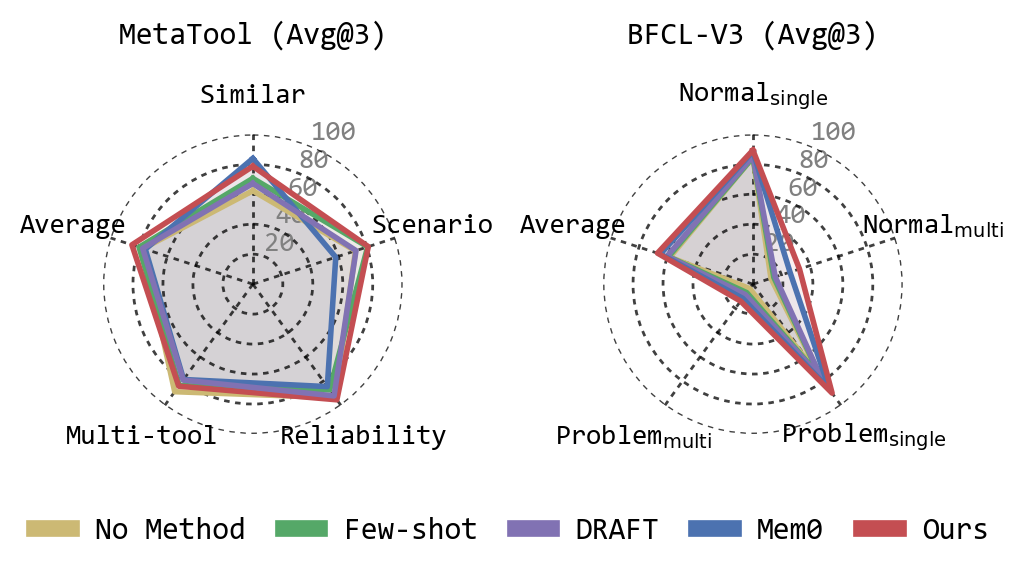

In [4]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.font_manager as fm
import matplotlib as mpl

# ---------- font (Consolas) ----------
font_path = '/Users/xiaocan/Toolmem/consola.ttf'  # change to your path
fm.fontManager.addfont(font_path)
matplotlib.rcParams['pdf.fonttype'] = 42
FONT_SIZE = 10  # <<< 统一在这里改

mpl.rcParams.update({
    "font.family": "Consolas",
    "font.sans-serif": ["Consolas", "DejaVu Sans"],
    "axes.unicode_minus": False,

    # ---- make ALL text the same size ----
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE+1,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE+1,
})

# ---------- colors ----------
colors = {
    "DRAFT": "#8172B3",  # purple
    "Few-shot":  "#55A868",  # green
    "No Method":     "#CCB974",  # yellow-brown
    "Mem0":      "#4C72B0",  # blue
    "Ours":      "#C44E52",  # red-brown
}

def radar(ax, labels, series_dict, title, colors, rmax=100, rticks=(20, 40, 60, 80, 100), title_y=1.25):
    series_pct = {k: [v * 100 for v in vals] for k, vals in series_dict.items()}

    N = len(labels)
    angles = np.linspace(0, 2*np.pi, N, endpoint=False)
    angles = np.concatenate([angles, [angles[0]]])

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)  # no fontsize -> use global

    ax.set_ylim(0, rmax)
    ax.set_yticks(list(rticks))
    ax.set_yticklabels([str(t) for t in rticks], color="gray")  # no fontsize -> use global

    ax.yaxis.grid(True, linestyle=(0, (2, 2)), linewidth=1.0, color="black", alpha=0.75)
    ax.xaxis.grid(True, linestyle=(0, (2, 2)), linewidth=1.0, color="black", alpha=0.75)
    ax.spines["polar"].set_visible(False)

    for name, vals in series_pct.items():
        vals_closed = vals + [vals[0]]
        c = colors.get(name, "#333333")
        ax.plot(angles, vals_closed, color=c, linewidth=2.0)
        ax.fill(angles, vals_closed, color=c, alpha=0.08)

    ax.set_title(title, y=title_y)  # no fontsize -> use global

# =========================
# Left: MetaTool Avg@3
# =========================
labels_meta = ["Similar", "Scenario", "Reliability", "Multi-tool", "Average"]
data_meta_avg = {
    "No Method": [0.6233, 0.7201, 0.9360, 0.8873, 0.7697],
    "Few-shot":  [0.7060, 0.8057, 0.8720, 0.8369, 0.7983],
    "Mem0":      [0.8387, 0.5818, 0.8453, 0.7866, 0.7547],
    "Ours":      [0.7867, 0.8101, 0.9540, 0.8417, 0.8488],
    "DRAFT": [0.6720, 0.7239, 0.9220, 0.7914, 0.7733]
}

# =========================
# Right: BFCL-V3 (4 dims + Average)
# =========================
labels_bfcl = [
    r"Normal$\mathrm{}_{\mathrm{single}}$",
    r"Normal$\mathrm{}_{\mathrm{multi}}$",
    r"Problem$\mathrm{}_{\mathrm{single}}$",
    r"Problem$\mathrm{}_{\mathrm{multi}}$  ",
    "Average",
]

bfcl_avg_axis = {"No Method": 0.5828, "Few-shot": 0.5929, "DRAFT": 0.6030, "Mem0": 0.6493, "Ours": 0.6696}
data_bfcl = {
    "No Method": [0.8458, 0.1267, 0.7679, 0.0367, bfcl_avg_axis["No Method"]],
    "Few-shot":  [0.8471, 0.1466, 0.7679, 0.0700, bfcl_avg_axis["Few-shot"]],
    "DRAFT":     [0.8549, 0.1566, 0.7779, 0.0866, bfcl_avg_axis["DRAFT"]],
    "Mem0":      [0.8862, 0.2600, 0.8691, 0.1166, bfcl_avg_axis["Mem0"]],
    "Ours":      [0.8940, 0.3267, 0.8988, 0.1400, bfcl_avg_axis["Ours"]],
}

fig, axes = plt.subplots(1, 2, figsize=(5.2, 3), dpi=200, subplot_kw=dict(polar=True))

radar(axes[0], labels_meta, data_meta_avg, "MetaTool (Avg@3)", colors)
radar(axes[1], labels_bfcl, data_bfcl, "BFCL-V3 (Avg@3)", colors)

legend_order = ["No Method", "Few-shot", "DRAFT", "Mem0", "Ours"]
handles = [Line2D([0], [0], color=colors[k], lw=6) for k in legend_order]

fig.legend(
    handles, legend_order,
    loc="lower center",
    bbox_to_anchor=(0.5, 0),
    ncol=5,
    frameon=False,
    handlelength=1.2,
    columnspacing=1.2,
)

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()


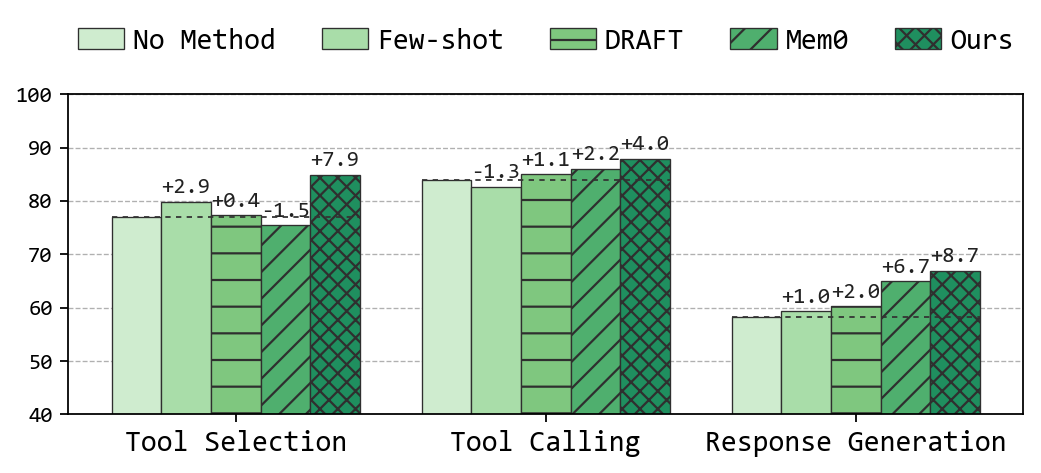

In [4]:
import numpy as np
import matplotlib.pyplot as plt

FONT_SIZE = 12
stages = ["Tool Selection", "Tool Calling", "Response Generation"]
methods = ["No Method", "Few-shot", "DRAFT", "Mem0", "Ours"]

vals = np.array([
    [76.97, 83.88, 58.28],  # No Method
    [79.83, 82.62, 59.29],  # Few-shot
    [77.33, 84.96, 60.30],  # DRAFT
    [75.47, 86.05, 64.93],  # Mem0
    [84.88, 87.89, 66.96],  # Ours
])

colors = ["#CFECCF", "#A9DDA9", "#7FC77F", "#4FAF6E", "#1F8F5F"]
# 花纹模式：从左到右越来越突出，No Method 无花纹
hatches = ["", "", "-", "//", "xxx"]  # 无花纹, 稀疏点, 稀疏斜线, 中等斜线, 交叉线

x = np.arange(len(stages))
bar_w = 0.16

fig, ax = plt.subplots(figsize=(7.7, 2.6), dpi=160)

# 以 No Method 作为基线
baseline = vals[0].copy()  # shape (3,)

# 先画每个 stage 上 No Method 的“贯穿虚线”（位于对应高度）
group_half_width = (len(methods) / 2) * bar_w  # 覆盖整组柱子的宽度范围
for j in range(len(stages)):
    yb = baseline[j]
    ax.hlines(
        y=yb,
        xmin=x[j] - group_half_width,
        xmax=x[j] + group_half_width,
        colors="#333333",
        linestyles=(0, (3, 3)),
        linewidth=0.8,
        zorder=5   # 关键：比柱子更大，避免被挡
)

# 画柱子 + 标注“相对 No Method 的提升”
for i, m in enumerate(methods):
    y = vals[i].copy()
    missing = np.isnan(y)

    y_plot = y.copy()
    y_plot[missing] = 0.0

    bars = ax.bar(
        x + (i - 2) * bar_w, y_plot, width=bar_w,
        color=colors[i], edgecolor="#2f2f2f", linewidth=0.6, label=m, zorder=2
    )
    
    # 应用花纹：从左到右越来越突出
    if hatches[i]:  # No Method 不需要花纹
        for bar in bars:
            bar.set_hatch(hatches[i])

    # 标签：No Method 自己不标；缺失不标；其余标 “+Δ”
    labels = []
    for j in range(len(stages)):
        if i == 0:
            labels.append("")
        elif missing[j]:
            labels.append("NA")
        else:
            delta = y[j] - baseline[j]
            labels.append(f"{delta:+.1f}")  # +x.x / -x.x

    texts = ax.bar_label(bars, labels=labels, padding=2,
                         fontsize=FONT_SIZE-2, color="#222222")
    for t in texts:
        if t.get_text():
            t.set_rotation(0)
            t.set_ha("center")
            t.set_va("bottom")

# # 缺失值位置标 NA（仍保留）
# draft_idx = methods.index("DRAFT")
# ax.text(x[0] + (draft_idx-2)*bar_w, 1.0, "NA",
#         ha="center", va="bottom", fontsize=FONT_SIZE-2, color="#555555")
# ax.set_xticks([])
ax.set_xticks(x)
ax.set_xticklabels(stages, fontsize=FONT_SIZE+1)
# ax.set_ylabel("Avg@3", fontsize=FONT_SIZE)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=1)
ax.set_ylim(40, 100)
for i, m in enumerate(methods):
    y = vals[i]
    missing = np.isnan(y)
    for j in range(len(stages)):
        if missing[j]:
            x_pos = x[j] + (i - 2) * bar_w
            ax.text(x_pos, 20 + 1.0, "NA", ha="center", va="bottom",
                    fontsize=FONT_SIZE-2, color="#222222", clip_on=False)
# 只保留一个 legend，并把间距调紧
handles, labels_ = ax.get_legend_handles_labels()
ax.legend(handles, labels_,
          ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.28),
          loc="upper center", fontsize=FONT_SIZE+1,
          columnspacing=1.6, handletextpad=0.3, handlelength=1.6, borderaxespad=0.4)
fig.patch.set_alpha(0)      # 图外透明
ax.set_facecolor("white")   # 图内(坐标轴区域)白色

plt.savefig("avg3_bar.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)
plt.savefig("avg3_bar.pdf", transparent=True, bbox_inches="tight", pad_inches=0.02)
plt.show()


In [ ]:
from dotenv import load_dotenv
import os

# 加载 .env 文件中的环境变量
load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
print(f"OpenAI API Key: {OPENAI_API_KEY}")

In [3]:
import requests
import json
import requests
import json

response = requests.post("http://localhost:8002/add_tool_call_result", json=
{'workspace_id': 'tool_workspace', 
 'tool_call_results': [
          {
            "create_time": "2025-12-05 17:51:34",
            "tool_name": "move_file",
            "context": "[{'role': 'user', 'content': \"Please use FileSystem tools to ffinish the following task:\\n\\n### Task Description\\n\\nClassify all files in the test directory into three categories based on their file size. Create three subdirectories and move files accordingly.\\n\\n### Task Objectives\\n\\n1. **Create three directories** in the test directory:\\n\\n   - `small_files/` - for files smaller than 300 bytes\\n   - `medium_files/` - for files between 300-700 bytes (inclusive)\\n   - `large_files/` - for files larger than 700 bytes\\n2. **Move all files** from the test directory into the appropriate subdirectory based on their size\\n3. **Handle all file types** - classify all files regardless of their extension (.txt, .jpg, .MOV, etc.)\\n\\n\\nNote: Based on your understanding, solve the task all at once by yourself, don't ask for my opinions on anything.\"}, {'role': 'tool_call', 'content': 'list_allowed_directories({})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'Allowed directories:\\n/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229'}}, {'role': 'tool_call', 'content': 'directory_tree({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool directory_tree: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}, {'role': 'tool_call', 'content': 'list_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': '[FILE] .DS_Store\\n[FILE] bear.jpg\\n[FILE] bridge.jpg\\n[FILE] bus.MOV\\n[FILE] random_file_1.txt\\n[FILE] random_file_2.txt\\n[FILE] random_file_3.txt\\n[FILE] road.MOV\\n[FILE] sg.jpg'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/.DS_Store\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 6148\\ncreated: Wed Aug 06 2025 20:59:51 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 20:59:51 GMT+0800 (中国标准时间)\\naccessed: Wed Aug 06 2025 21:06:09 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/bear.jpg\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 108104\\ncreated: Wed Aug 06 2025 12:31:58 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 12:31:58 GMT+0800 (中国标准时间)\\naccessed: Wed Dec 03 2025 17:09:02 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/bridge.jpg\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 205655\\ncreated: Wed Aug 06 2025 16:24:56 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 16:24:56 GMT+0800 (中国标准时间)\\naccessed: Wed Dec 03 2025 17:09:02 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/bus.MOV\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 15706882\\ncreated: Fri Jul 25 2025 10:48:27 GMT+0800 (中国标准时间)\\nmodified: Fri Jul 25 2025 10:48:27 GMT+0800 (中国标准时间)\\naccessed: Wed Aug 06 2025 23:48:50 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_1.txt\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 111\\ncreated: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\naccessed: Thu Dec 04 2025 05:45:26 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_2.txt\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 634\\ncreated: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\naccessed: Thu Dec 04 2025 05:45:26 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_3.txt\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 97\\ncreated: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\nmodified: Wed Aug 06 2025 16:28:18 GMT+0800 (中国标准时间)\\naccessed: Thu Dec 04 2025 05:45:26 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/road.MOV\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 15191645\\ncreated: Sat Jul 26 2025 15:19:15 GMT+0800 (中国标准时间)\\nmodified: Sat Jul 26 2025 15:19:15 GMT+0800 (中国标准时间)\\naccessed: Wed Aug 06 2025 23:48:50 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'get_file_info({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/sg.jpg\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'size: 332545\\ncreated: Wed Jul 09 2025 23:40:02 GMT+0800 (中国标准时间)\\nmodified: Wed Jul 09 2025 23:40:02 GMT+0800 (中国标准时间)\\naccessed: Wed Dec 03 2025 17:08:58 GMT+0800 (中国标准时间)\\nisDirectory: false\\nisFile: true\\npermissions: 644'}}, {'role': 'tool_call', 'content': 'create_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/small_files\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'Successfully created directory /Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/small_files'}}, {'role': 'tool_call', 'content': 'create_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/medium_files\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'Successfully created directory /Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/medium_files'}}, {'role': 'tool_call', 'content': 'create_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/large_files\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': 'Successfully created directory /Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/large_files'}}, {'role': 'tool_call', 'content': 'move_file({\"source\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_1.txt\", \"destination\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/small_files/random_file_1.txt\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}, {'role': 'tool_call', 'content': 'move_file({\"source\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_3.txt\", \"destination\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/small_files/random_file_3.txt\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}, {'role': 'tool_call', 'content': 'list_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': '[FILE] .DS_Store\\n[FILE] bear.jpg\\n[FILE] bridge.jpg\\n[FILE] bus.MOV\\n[DIR] large_files\\n[DIR] medium_files\\n[FILE] random_file_2.txt\\n[FILE] road.MOV\\n[FILE] sg.jpg\\n[DIR] small_files'}}, {'role': 'tool_call', 'content': 'list_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/small_files\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': '[FILE] random_file_1.txt\\n[FILE] random_file_3.txt'}}, {'role': 'tool_call', 'content': 'move_file({\"source\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/random_file_2.txt\", \"destination\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/medium_files/random_file_2.txt\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}, {'role': 'tool_call', 'content': 'list_directory({\"path\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/medium_files\"})'}, {'role': 'tool_result', 'content': {'success': True, 'output': '[FILE] random_file_2.txt'}}, {'role': 'tool_call', 'content': 'move_file({\"source\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/.DS_Store\", \"destination\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/large_files/.DS_Store\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}, {'role': 'tool_call', 'content': 'move_file({\"source\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/bear.jpg\", \"destination\": \"/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/large_files/bear.jpg\"})'}, {'role': 'tool_result', 'content': {'success': False, 'output': 'MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \"expected\": \"string\",\\n    \"code\": \"invalid_type\",\\n    \"path\": [\\n      \"content\"\\n    ],\\n    \"message\": \"Invalid input: expected string, received array\"\\n  }\\n]'}}]",
            "config": "/Users/xiaocan/Toolmem/experiment/mcpmark/config.json",
            "input": {
              "source": "/Users/xiaocan/Toolmem/experiment/mcpmark/.mcpmark_backups/backup_filesystem_file_property_size_classification_56229/bear.jpg",
            },
            "output": "\"MCP error -32602: Output validation error: Invalid structured content for tool move_file: [\\n  {\\n    \\\"expected\\\": \\\"string\\\",\\n    \\\"code\\\": \\\"invalid_type\\\",\\n    \\\"path\\\": [\\n      \\\"content\\\"\\n    ],\\n    \\\"message\\\": \\\"Invalid input: expected string, received array\\\"\\n  }\\n]\"",
            "token_cost": 0,
            "success": False,
            "time_cost": 0.0,
  "source_task": "当前的任务名称"
}
      ]
      }
)
data = response.json() # 这是一个 Python dict/list
print(data)
# print(json.dumps(data, indent=2, ensure_ascii=False))

{'answer': 'Processed 1 tool(s): 1 updated, 0 newly created\n\n[Updated] move_file\n  Total calls: 2\n  Recent calls: 0/2 successful, avg score: 7.50\n\nDeduplication Summary:\n  Skipped before evaluation: 0\n  Total new calls (evaluated): 1\n  Added to memory: 1', 'messages': [], 'success': True, 'metadata': {'deleted_memory_ids': ['6f950ec6cef442a5b1c08c9e304859e8'], 'memory_list': [{'workspace_id': 'tool_workspace', 'memory_id': '6f950ec6cef442a5b1c08c9e304859e8', 'memory_type': 'tool', 'when_to_use': 'move_file', 'content': '', 'score': 0.9999999999999999, 'time_created': '2026-01-28 18:18:42', 'time_modified': '2026-01-28 18:19:16', 'author': '', 'metadata': {}, 'config': '/Users/xiaocan/Toolmem/experiment/mcpmark/config.json', 'tool_call_results': [{'create_time': '2025-12-05 17:51:34', 'tool_name': 'move_file', 'context': '[{\'role\': \'user\', \'content\': "Please use FileSystem tools to ffinish the following task:\\n\\n### Task Description\\n\\nClassify all files in the test d

In [6]:
import requests
import json
response = requests.post("http://localhost:8002/summary_tool_memory", 
json={    "workspace_id": "toole",
    "tool_names": "timeport",
'source_task': 'SymptomSearch-AppointmentRegistration-level-2-1.jsonl'})

data = response.json() # 这是一个 Python dict/list
print(json.dumps(data, indent=2, ensure_ascii=False))



{
  "answer": "Processed 1 tool(s): 1 summarized, 0 skipped\n\nTool: timeport\n1. **Core Function**: 'timeport' is a time-travel game designed for interactive historical learning. Use it when the user explicitly requests or implies immersive, experiential engagement with a specific historical period (e.g., “Take me back to…” or “Experience ancient Rome”).\n\n2. **Success Patterns**: Successful invocations occur when the query clearly references a historical era or civilization and seeks an experiential or interactive encounter rather than factual summaries. No input parameters are required.\n\n3. **Common Issues**: Avoid using 'timeport' for ambiguous requests (e.g., “this experience”) or when the user seeks encyclopedic, non-interactive information—even if historically themed—as it may be suboptimal despite being marginally relevant.\n\n4. **Best Practices**: \n   - Only invoke 'timeport' when the user’s intent aligns with immersive time travel, not general historical inquiry.\n   - P

In [7]:
# Retrieve tool guidelines before use
response = requests.post("http://localhost:8002/retrieve_tool_memory", json={
  "workspace_id": "toole",
    "tool_names": "timeport",
})
data = response.json()['metadata'] # 这是一个 Python dict/list
print(data)

[{'content': "1. **Core Function**: 'timeport' is a time-travel game designed for interactive historical learning. Use it when the user explicitly requests or implies immersive, experiential engagement with a specific historical period (e.g., “Take me back to…” or “Experience ancient Rome”).\n\n2. **Success Patterns**: Successful invocations occur when the query clearly references a historical era or civilization and seeks an experiential or interactive encounter rather than factual summaries. No input parameters are required.\n\n3. **Common Issues**: Avoid using 'timeport' for ambiguous requests (e.g., “this experience”) or when the user seeks encyclopedic, non-interactive information—even if historically themed—as it may be suboptimal despite being marginally relevant.\n\n4. **Best Practices**: \n   - Only invoke 'timeport' when the user’s intent aligns with immersive time travel, not general historical inquiry.\n   - Prioritize clarity: if the historical context or experiential goal